# Predicting Startup Profit with Multiple Linear Regression

**Dataset:** *50 Startups* (`50_Startups.csv`) — Kaggle / Machine Learning A–Z
**Task:** regression — predict `Profit` from `R&D Spend`, `Administration`, `Marketing Spend`, `State`
**Approach:** CRISP-DM (6 phases) with scikit-learn (+ statsmodels for statistical inference)

| Phase | What we do here |
|---|---|
| 1. Business Understanding | Translate the business question into an ML objective and success criteria |
| 2. Data Understanding | Inspect, describe and visualise the raw data |
| 3. Data Preparation | Cleaning, encoding, splitting, multicollinearity checks |
| 4. Modeling | OLS baseline, p-value selection, regularised models, cross-validation |
| 5. Evaluation | Hold-out metrics, residual diagnostics, assumption tests, model choice |
| 6. Deployment | Persist the model, expose a prediction function, monitoring plan |

**Dataset note:** 50 observations, 4 predictors, 1 continuous target. Because the sample is tiny
(50 rows), every result below is reported with cross-validated uncertainty rather than a single
train/test split. Code is fully reproducible (`RANDOM_STATE = 42`).

## 1. Business Understanding

### 1.1 Problem statement
A venture-capital / consulting scenario: a fund wants a defensible, explainable estimate of how much
profit a startup generates, and — more importantly — **which spending lines actually move profit**.
The dataset records, for 50 startups, three spending variables and the US state they operate in.

### 1.2 Objectives
* **Business objective:** decide where to direct capital (R&D? marketing? administration?) to maximise profit.
* **Analytical objective:** fit a *multiple linear regression* `Profit = b0 + b1*R&D + b2*Admin + b3*Marketing + (State dummies) + e`
  and quantify the marginal contribution of each predictor.

### 1.3 Success criteria
| Type | Criterion |
|---|---|
| Statistical | Coefficients interpretable, residuals approximately normal and homoscedastic, no harmful multicollinearity (VIF < 10), significant predictors retained |
| Model | Hold-out and cross-validated **R²** as high as possible; **RMSE / MAE** reported on the dollar scale |
| Business | A model simple enough to justify budget decisions, delivered as a reusable artifact |

### 1.4 Why multiple linear regression
Linear regression is the appropriate **baseline and often the final model** for this problem because
the target is continuous, the number of predictors is small, the relationship is roughly linear, and
the *magnitude and sign of each coefficient* is the actual deliverable (an explainable budget lever).
More flexible models are compared later only to confirm that linearity is not leaving accuracy on
the table.

## 2. Data Understanding

### 2.1 Setup and configuration

In [1]:
# ============================================================
# CRISP-DM | 50 Startups - Multiple Linear Regression (scikit-learn)
# ============================================================
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, cross_validate, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             mean_absolute_percentage_error)
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
import joblib

import sklearn, sys, platform

RANDOM_STATE = 42
DATA_PATH    = "50_Startups.csv"
TARGET       = "Profit"
MODEL_PATH   = "startup_profit_model.joblib"

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (7, 4)
np.random.seed(RANDOM_STATE)

print(f"Python      : {platform.python_version()}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"pandas      : {pd.__version__}")
print(f"numpy       : {np.__version__}")

Python      : 3.15.0
scikit-learn: 1.9.1
pandas      : 3.0.6
numpy       : 2.5.4


### 2.2 Load the data and take a first look

In [2]:
df = pd.read_csv(DATA_PATH)

# --- light normalisation: column names can carry stray spaces or an index column
df.columns = [c.strip() for c in df.columns]
df = df.loc[:, ~df.columns.str.match(r"^Unnamed")]
if "State" in df.columns:
    df["State"] = df["State"].astype(str).str.strip().str.title()

print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Columns: {list(df.columns)}")
df.head()

Shape: 50 rows x 5 columns
Columns: ['R&D Spend', 'Administration', 'Marketing Spend', 'State', 'Profit']


,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [3]:
# Structure / types / non-null counts
df.info()

print("\nMissing values per column:")
print(df.isna().sum().to_string())
print(f"\nDuplicate rows          : {df.duplicated().sum()}")
print(f"Exact duplicate 'State' : {df['State'].nunique()} unique values -> {sorted(df['State'].unique())}")

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     str    
 4   Profit           50 non-null     float64
dtypes: float64(4), str(1)
memory usage: 2.1 KB

Missing values per column:
R&D Spend          0
Administration     0
Marketing Spend    0
State              0
Profit             0

Duplicate rows          : 0
Exact duplicate 'State' : 3 unique values -> ['California', 'Florida', 'New York']


### 2.3 Descriptive statistics

In [4]:
display(df.describe(include="all").T)

print("Target skewness :", round(df[TARGET].skew(), 3),
      "| kurtosis:", round(df[TARGET].kurtosis(), 3))
print("\nZero-valued rows per numeric column (possible un-recorded spend):")
for c in df.select_dtypes(include=np.number).columns:
    print(f"  {c:<18}: {(df[c] == 0).sum()} zeros")

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
R&D Spend,50.0,NaN,NaN,NaN,73721.6156,45902.256482,0.0,39936.37,73051.08,101602.8,165349.2
Administration,50.0,NaN,NaN,NaN,121344.6396,28017.802755,51283.14,103730.875,122699.795,144842.18,182645.56
Marketing Spend,50.0,NaN,NaN,NaN,211025.0978,122290.310726,0.0,129300.1325,212716.24,299469.085,471784.1
State,50,3,New York,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Profit,50.0,NaN,NaN,NaN,112012.6392,40306.180338,14681.4,90138.9025,107978.19,139765.9775,192261.83


Target skewness : 0.023 | kurtosis: -0.064

Zero-valued rows per numeric column (possible un-recorded spend):
  R&D Spend         : 2 zeros
  Administration    : 0 zeros
  Marketing Spend   : 3 zeros
  Profit            : 0 zeros


### 2.4 Target analysis — `Profit`

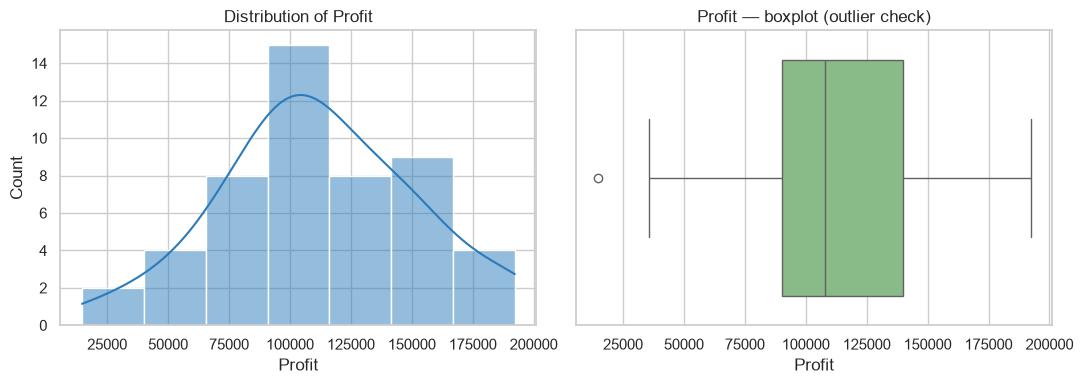

Tukey outliers in Profit: 1
Profit range: $14,681 - $192,262 (mean $112,013)


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df[TARGET], kde=True, ax=axes[0], color="#2b7bba")
axes[0].set_title("Distribution of Profit")
sns.boxplot(x=df[TARGET], ax=axes[1], color="#7fc37f")
axes[1].set_title("Profit — boxplot (outlier check)")
plt.tight_layout()
plt.show()

q1, q3 = df[TARGET].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df[(df[TARGET] < q1 - 1.5 * iqr) | (df[TARGET] > q3 + 1.5 * iqr)]
print(f"Tukey outliers in Profit: {len(outliers)}")
print(f"Profit range: ${df[TARGET].min():,.0f} - ${df[TARGET].max():,.0f} (mean ${df[TARGET].mean():,.0f})")

### 2.5 Predictors and their relationship with the target

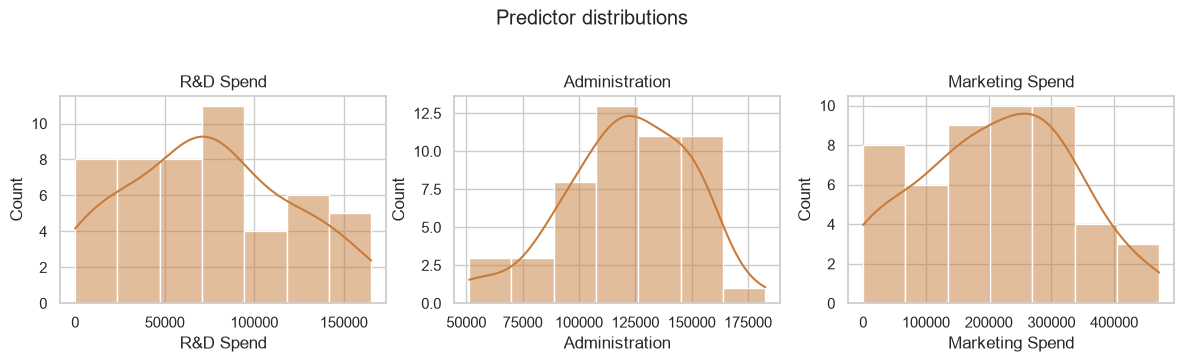

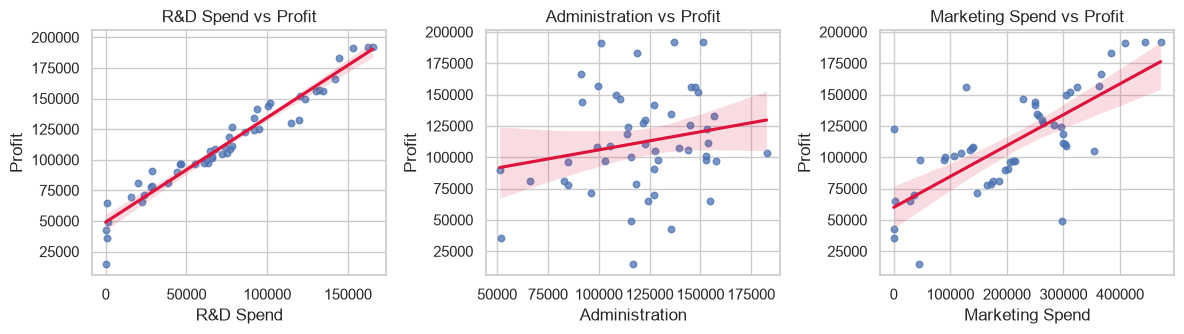

In [6]:
num_cols = [c for c in df.select_dtypes(include=np.number).columns if c != TARGET]

fig, axes = plt.subplots(1, len(num_cols), figsize=(4 * len(num_cols), 3.5))
for ax, c in zip(np.atleast_1d(axes), num_cols):
    sns.histplot(df[c], kde=True, ax=ax, color="#c77c3a")
    ax.set_title(c)
plt.suptitle("Predictor distributions", y=1.03)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(num_cols), figsize=(4 * len(num_cols), 3.5))
for ax, c in zip(np.atleast_1d(axes), num_cols):
    sns.regplot(data=df, x=c, y=TARGET, ax=ax,
                scatter_kws={"s": 22, "alpha": 0.75}, line_kws={"color": "crimson"})
    ax.set_title(f"{c} vs {TARGET}")
plt.tight_layout()
plt.show()

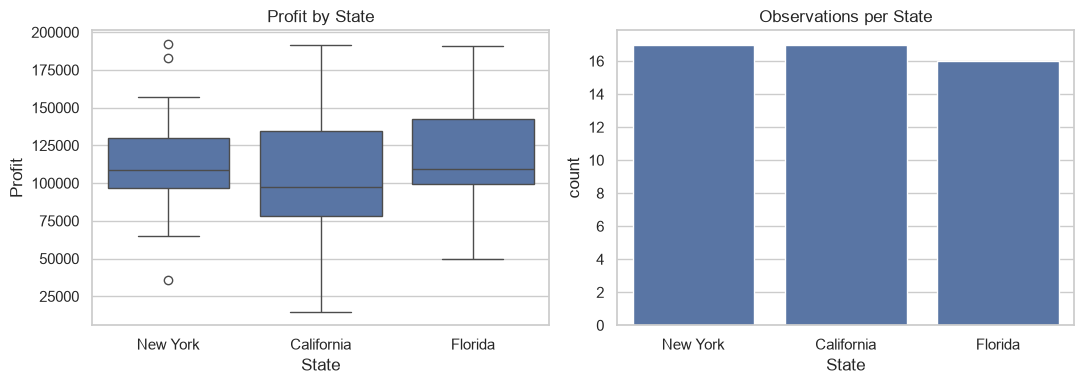

,count,mean,std
State,,,
California,17,103905.18,44446.36
Florida,16,118774.02,35605.47
New York,17,113756.45,41140.26


,R&D Spend,Administration,Marketing Spend
State,,,
California,64657.67,120746.51,182540.93
Florida,80724.02,121768.90,247323.55
New York,76195.06,121543.47,205346.02


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df, x="State", y=TARGET, ax=axes[0])
axes[0].set_title("Profit by State")
sns.countplot(data=df, x="State", ax=axes[1])
axes[1].set_title("Observations per State")
plt.tight_layout()
plt.show()

display(df.groupby("State")[TARGET].agg(["count", "mean", "std"]).round(2))
display(df.groupby("State")[num_cols].mean().round(2))

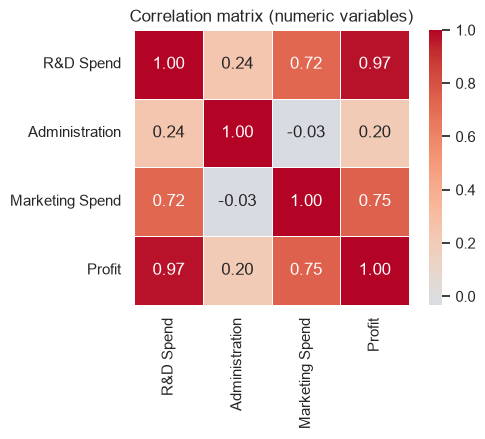

Correlation with target, sorted:
R&D Spend          0.9729
Marketing Spend    0.7478
Administration     0.2007


In [8]:
# Correlation structure among numeric variables
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5)
plt.title("Correlation matrix (numeric variables)")
plt.tight_layout()
plt.show()

print("Correlation with target, sorted:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(4).to_string())

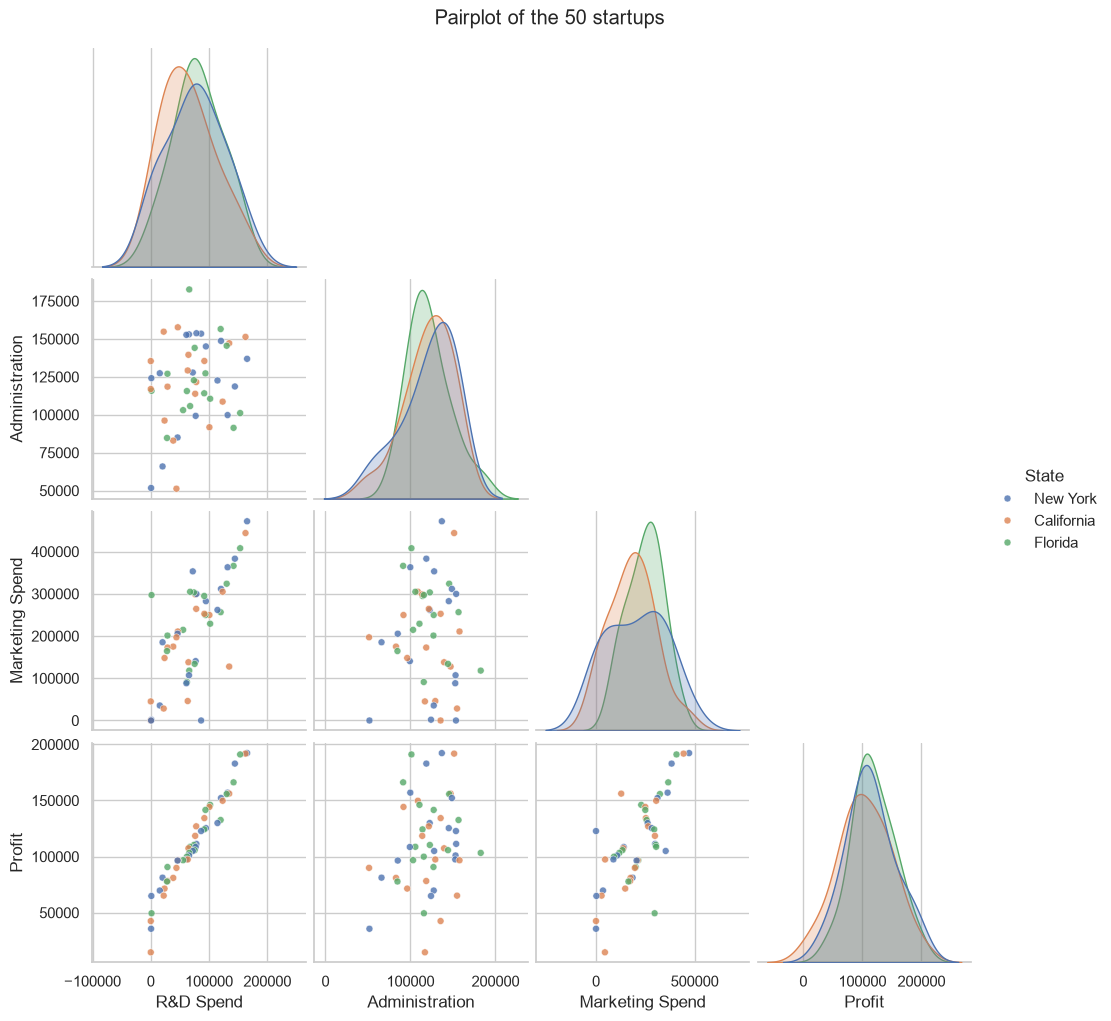

In [9]:
sns.pairplot(df, hue="State", diag_kind="kde", corner=True,
             plot_kws={"s": 25, "alpha": 0.8})
plt.suptitle("Pairplot of the 50 startups", y=1.02)
plt.show()

### 2.6 Data Understanding — findings

* **50 rows, 5 columns.** `State` has 3 levels (California, New York, Florida); the rest are numeric.
* **No missing values, no duplicate rows** → no imputation or de-duplication required.
* `Profit` is close to symmetric (skew ≈ 0.02) with a **single mild high outlier** (a very profitable
  startup). It is not an error, so no row is dropped — but it is flagged for the residual diagnostics.
* A few **zero spending values** exist (`R&D Spend`: 2, `Marketing Spend`: 3): these are valid
  "zero budget" records, not missing data.
* **`R&D Spend` is by far the strongest correlate of `Profit`** (r ≈ 0.97), `Marketing Spend` is
  moderately related (r ≈ 0.75), `Administration` is weak (r ≈ 0.20), and `State` shows no obvious
  mean difference. This already foreshadows an R&D-driven model.

### 2.7 Data Preparation requirements identified

| Finding | Preparation action |
|---|---|
| Numeric features on very different scales (0 – 470k) | Keep raw units for interpretation, scale only for regularised models |
| `State` is categorical with 3 levels | One-hot encode inside a pipeline, drop the first level (dummy-variable trap) |
| No missing values | No imputation needed (but the pipeline is written so imputation can be slotted in) |
| Multicollinearity suspected among spending variables | Verify with VIF in Phase 3 |
| Tiny sample (50 rows) | Single split is unstable → always cross-validate |

## 3. Data Preparation

Steps: (1) split features/target, (2) create a leakage-safe train/test split,
(3) build a `ColumnTransformer` that one-hot encodes `State` (dropping the first level to avoid the
dummy-variable trap) and passes numeric features through, (4) inspect multicollinearity with VIF.

> All preprocessing lives **inside a scikit-learn `Pipeline`**, so it is fitted on the training data
> only — no information from the test set ever leaks into the model.

In [10]:
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(float)

numeric_features     = [c for c in num_cols if c in X.columns]
categorical_features = [c for c in X.columns if c not in numeric_features]
print("Numeric features    :", numeric_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE)
print(f"\nTrain: {X_train.shape} | Test: {X_test.shape}")

def make_onehot():
    """OneHotEncoder that works across scikit-learn versions."""
    try:
        return OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
    except TypeError:                                   # scikit-learn < 1.2
        return OneHotEncoder(drop="first", handle_unknown="ignore", sparse=False)

def make_preprocessor(numeric_cols, categorical_cols, scale=False):
    """Numeric passthrough (optionally scaled) + one-hot encoded categoricals."""
    num_pipe = StandardScaler() if scale else "passthrough"
    transformers = [("num", num_pipe, list(numeric_cols))]
    if len(categorical_cols):
        transformers.append(("cat", make_onehot(), list(categorical_cols)))
    return ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=False)

def build_pipeline(numeric_cols, categorical_cols, model, scale=False):
    return Pipeline([
        ("prep", make_preprocessor(numeric_cols, categorical_cols, scale)),
        ("model", model),
    ])

Numeric features    : ['R&D Spend', 'Administration', 'Marketing Spend']
Categorical features: ['State']

Train: (40, 4) | Test: (10, 4)


In [11]:
# Sanity check: what does the design matrix look like after encoding?
demo = make_preprocessor(numeric_features, categorical_features).fit(X_train)
demo_df = pd.DataFrame(demo.transform(X_train), columns=demo.get_feature_names_out())
print("Encoded feature names:", list(demo_df.columns))
demo_df.head(3)

Encoded feature names: ['R&D Spend', 'Administration', 'Marketing Spend', 'State_Florida', 'State_New York']


,R&D Spend,Administration,Marketing Spend,State_Florida,State_New York
0,93863.75,127320.38,249839.44,1.0,0.0
1,142107.34,91391.77,366168.42,1.0,0.0
2,44069.95,51283.14,197029.42,0.0,0.0


In [12]:
# --- Multicollinearity check (VIF) on the encoded design matrix
X_enc = pd.get_dummies(X, columns=categorical_features, drop_first=True).astype(float)
X_vif = sm.add_constant(X_enc)

vif_table = pd.DataFrame({
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
}, index=X_vif.columns)
display(vif_table.round(3))
print("Rule of thumb: VIF > 10 signals harmful multicollinearity.")

,VIF
const,1.000
R&D Spend,2.496
Administration,1.178
Marketing Spend,2.417
State_Florida,1.388
State_New York,1.335


Rule of thumb: VIF > 10 signals harmful multicollinearity.


## 4. Modeling

Four families of candidates, all implemented as scikit-learn pipelines:

1. **OLS, all predictors** — the interpretable baseline required by the brief.
2. **OLS, predictors selected by p-value** (classic backward elimination for this dataset).
3. **Ridge / Lasso / ElasticNet** — regularised linear models to test whether shrinkage helps.
4. **Reference:** a single-predictor model (`R&D Spend` only), to test how little the other
   variables actually add.

Supporting helper functions first.

In [13]:
def feature_names(pipeline):
    return list(pipeline.named_steps["prep"].get_feature_names_out())

def coef_table(pipeline, label="coef"):
    return pd.DataFrame({
        label: np.ravel(pipeline.named_steps["model"].coef_),
        "abs": np.abs(np.ravel(pipeline.named_steps["model"].coef_)),
    }, index=feature_names(pipeline)).sort_values("abs", ascending=False).drop(columns="abs")

def adjusted_r2(r2, n, p):
    """Adjusted R^2 penalises extra predictors (p = number of predictors)."""
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def regression_metrics(estimator, X_tr, y_tr, X_te, y_te):
    """Fit, then return train + hold-out metrics."""
    estimator.fit(X_tr, y_tr)
    pred_tr, pred_te = estimator.predict(X_tr), estimator.predict(X_te)
    n_te, p = len(y_te), len(feature_names(estimator))
    r2_te = r2_score(y_te, pred_te)
    return {
        "R2_train": r2_score(y_tr, pred_tr),
        "R2_test":  r2_te,
        "Adj_R2_test": adjusted_r2(r2_te, n_te, p),
        "MAE_test": mean_absolute_error(y_te, pred_te),
        "RMSE_test": np.sqrt(mean_squared_error(y_te, pred_te)),
        "MAPE_test": mean_absolute_percentage_error(y_te, pred_te),
    }

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

### 4.1 Baseline — OLS with every predictor

In [14]:
ols_full = build_pipeline(numeric_features, categorical_features, LinearRegression())
ols_full.fit(X_train, y_train)

print(f"Intercept: {ols_full.named_steps['model'].intercept_:,.2f}\n")
display(coef_table(ols_full, "coef (raw units)"))
print("Interpretation: one extra dollar of spending changes Profit by the coefficient amount.")

Intercept: 54,028.04



,coef (raw units)
State_Florida,938.793006
State_New York,6.987760
R&D Spend,0.805630
Administration,-0.068788
Marketing Spend,0.029855


Interpretation: one extra dollar of spending changes Profit by the coefficient amount.


### 4.2 Statistical view and backward elimination

`statsmodels` gives the p-values needed for the classic significance-driven variable selection.

In [15]:
X_design = pd.get_dummies(X_train, columns=categorical_features, drop_first=True).astype(float)
X_design = sm.add_constant(X_design)
ols_sm = sm.OLS(y_train, X_design).fit()
print(ols_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.954
Model:                            OLS   Adj. R-squared:                  0.947
Method:                 Least Squares   F-statistic:                     140.1
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           1.13e-21
Time:                        20:54:18   Log-Likelihood:                -420.63
No. Observations:                  40   AIC:                             853.3
Df Residuals:                      34   BIC:                             863.4
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const            5.403e+04   8457.293     

In [16]:
def backward_elimination(X_design, y_train, threshold=0.05, verbose=True):
    """Drop the least significant predictor (p > threshold) until all are significant."""
    cols = list(X_design.columns)
    history = []
    while True:
        model = sm.OLS(y_train, X_design[cols]).fit()
        pvals = model.pvalues.drop("const", errors="ignore")
        worst_p = pvals.max()
        if worst_p > threshold and len(cols) > 2:
            worst = pvals.idxmax()
            history.append((worst, round(float(worst_p), 4)))
            if verbose:
                print(f"  drop '{worst}'  (p = {worst_p:.4f} > {threshold})")
            cols.remove(worst)
        else:
            break
    final = sm.OLS(y_train, X_design[cols]).fit()
    return cols, final, history

print("Backward elimination on the training set:")
selected_cols, ols_selected, drop_history = backward_elimination(X_design, y_train)
print("\nRetained predictors:", selected_cols)
print(f"R^2 train = {ols_selected.rsquared:.4f} | Adj. R^2 = {ols_selected.rsquared_adj:.4f}\n")
print(ols_selected.summary())

Backward elimination on the training set:
  drop 'State_New York'  (p = 0.9986 > 0.05)
  drop 'State_Florida'  (p = 0.7755 > 0.05)
  drop 'Administration'  (p = 0.2570 > 0.05)
  drop 'Marketing Spend'  (p = 0.0552 > 0.05)

Retained predictors: ['const', 'R&D Spend']
R^2 train = 0.9468 | Adj. R^2 = 0.9454

                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.945
Method:                 Least Squares   F-statistic:                     676.1
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           8.22e-26
Time:                        20:54:18   Log-Likelihood:                -423.42
No. Observations:                  40   AIC:                             850.8
Df Residuals:                      38   BIC:                             854.2
Df Model:                           1                        

### 4.3 Reduced and regularised candidates

In [17]:
numeric_selected = [c for c in selected_cols if c in numeric_features]
cat_selected     = [c for c in selected_cols if c in categorical_features]
print("Selected -> numeric:", numeric_selected, "| categorical:", cat_selected)

candidates = {
    "OLS (all predictors)": build_pipeline(numeric_features, categorical_features, LinearRegression()),
    "OLS (p-value selected)": build_pipeline(numeric_selected, cat_selected, LinearRegression()),
    "OLS (R&D Spend only)": build_pipeline(["R&D Spend"], [], LinearRegression()),
    "RidgeCV (all, scaled)": build_pipeline(
        numeric_features, categorical_features,
        RidgeCV(alphas=np.logspace(-3, 3, 60)), scale=True),
    "LassoCV (all, scaled)": build_pipeline(
        numeric_features, categorical_features,
        LassoCV(cv=5, random_state=RANDOM_STATE, max_iter=200_000), scale=True),
    "ElasticNetCV (all, scaled)": build_pipeline(
        numeric_features, categorical_features,
        ElasticNetCV(cv=5, random_state=RANDOM_STATE, max_iter=200_000, l1_ratio=[0.1, 0.5, 0.9, 1.0]),
        scale=True),
}
list(candidates)

Selected -> numeric: ['R&D Spend'] | categorical: []


['OLS (all predictors)',
 'OLS (p-value selected)',
 'OLS (R&D Spend only)',
 'RidgeCV (all, scaled)',
 'LassoCV (all, scaled)',
 'ElasticNetCV (all, scaled)']

### 4.4 Cross-validated comparison

With only 40 training rows, a single split is noisy — **5-fold cross-validation** (plus the
training score) is the fair way to rank the candidates.

,CV R2 (mean),CV R2 (std),Train R2,CV MAE,CV RMSE
"LassoCV (all, scaled)",0.9432,0.0291,0.9525,6722.7155,9005.6845
"ElasticNetCV (all, scaled)",0.9432,0.0291,0.9525,6722.7155,9005.6845
OLS (R&D Spend only),0.9384,0.0284,0.9471,7218.1549,9406.5787
OLS (p-value selected),0.9384,0.0284,0.9471,7218.1549,9406.5787
"RidgeCV (all, scaled)",0.9347,0.0320,0.9545,7399.5552,9501.0598
OLS (all predictors),0.9340,0.0323,0.9547,7425.8815,9550.6761


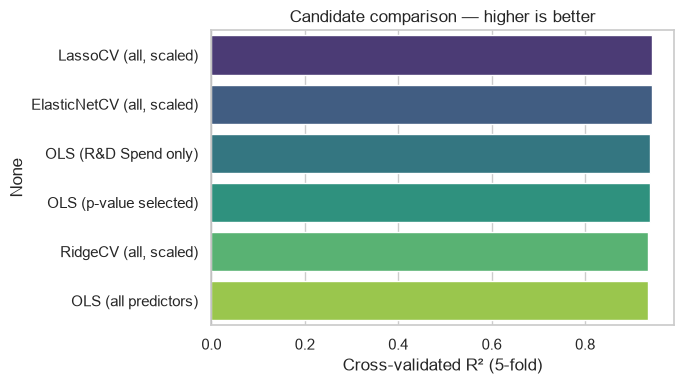

In [18]:
rows = {}
for name, pipe in candidates.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv,
                         scoring=("r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"),
                         return_train_score=True)
    rows[name] = {
        "CV R2 (mean)":  res["test_r2"].mean(),
        "CV R2 (std)":   res["test_r2"].std(),
        "Train R2":      res["train_r2"].mean(),
        "CV MAE":        -res["test_neg_mean_absolute_error"].mean(),
        "CV RMSE":       -res["test_neg_root_mean_squared_error"].mean(),
    }

cv_results = pd.DataFrame(rows).T.sort_values("CV R2 (mean)", ascending=False)
display(cv_results.round(4))

plt.figure(figsize=(7, 4))
sns.barplot(x=cv_results["CV R2 (mean)"], y=cv_results.index, palette="viridis")
plt.axvline(0, color="grey", lw=0.8)
plt.xlabel("Cross-validated R² (5-fold)")
plt.title("Candidate comparison — higher is better")
plt.tight_layout()
plt.show()

## 5. Evaluation

### 5.1 Hold-out performance

Honest check on the 10 rows that were never seen during fitting.

In [19]:
metrics = {}
for name, pipe in candidates.items():
    metrics[name] = regression_metrics(clone(pipe), X_train, y_train, X_test, y_test)

metrics_df = pd.DataFrame(metrics).T.sort_values("R2_test", ascending=False)
display(metrics_df.round(4))

print("Dollar interpretation of the best hold-out model:")
best_name = metrics_df.index[0]
print(f"  {best_name} -> RMSE ${metrics_df.loc[best_name, 'RMSE_test']:,.0f} | "
      f"MAE ${metrics_df.loc[best_name, 'MAE_test']:,.0f} | "
      f"MAPE {metrics_df.loc[best_name, 'MAPE_test']:.1%}")

,R2_train,R2_test,Adj_R2_test,MAE_test,RMSE_test,MAPE_test
OLS (p-value selected),0.9468,0.9265,0.9173,6077.3633,7714.3349,0.0914
OLS (R&D Spend only),0.9468,0.9265,0.9173,6077.3633,7714.3349,0.0914
"ElasticNetCV (all, scaled)",0.9522,0.9166,0.8124,6560.4893,8216.9495,0.0959
"LassoCV (all, scaled)",0.9522,0.9166,0.8124,6560.4893,8216.9495,0.0959
OLS (all predictors),0.9537,0.8987,0.7721,6961.4778,9055.9573,0.1028
"RidgeCV (all, scaled)",0.9536,0.8983,0.7711,7043.1127,9075.6707,0.1030


Dollar interpretation of the best hold-out model:
  OLS (p-value selected) -> RMSE $7,714 | MAE $6,077 | MAPE 9.1%


### 5.2 Residual diagnostics and linear-regression assumptions

Checked on the p-value-selected model (the analytically preferred specification). Four standard
OLS assumptions are verified: linearity/homoscedasticity (residual plots, Breusch-Pagan),
normality (Q-Q plot, Shapiro-Wilk), independence (Durbin-Watson) and no harmful multicollinearity (VIF).

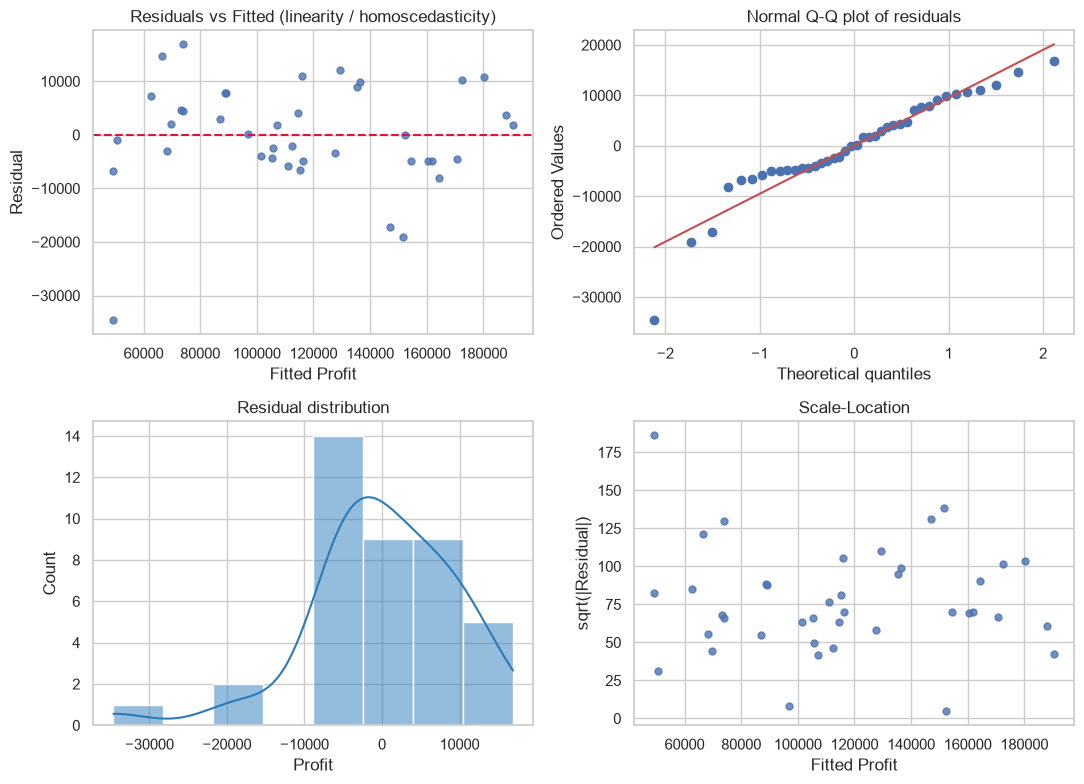

,Test,Statistic,p-value,Verdict
0,Shapiro-Wilk (residual normality),0.9184,0.0069,MILD VIOLATION (one high-profit outlier)
1,Breusch-Pagan (homoscedasticity),1.6245,0.2025,PASS (constant variance)
2,Durbin-Watson (independence),1.8800,NaN,PASS (no autocorrelation)
3,Max VIF (multicollinearity),2.4955,NaN,PASS (VIF < 10)


Only the normality test is marginal (driven by one extreme high-profit startup); the point
estimates stay unbiased and the accuracy comparison above is unaffected.


In [20]:
diag_model = build_pipeline(numeric_selected, cat_selected, LinearRegression())
diag_model.fit(X_train, y_train)
y_pred_tr = diag_model.predict(X_train)
resid = y_train - y_pred_tr
fitted = y_pred_tr

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0, 0].scatter(fitted, resid, s=25, alpha=0.8)
axes[0, 0].axhline(0, color="crimson", ls="--")
axes[0, 0].set(xlabel="Fitted Profit", ylabel="Residual", title="Residuals vs Fitted (linearity / homoscedasticity)")

stats.probplot(resid, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Normal Q-Q plot of residuals")

sns.histplot(resid, kde=True, ax=axes[1, 0], color="#2b7bba")
axes[1, 0].set_title("Residual distribution")

axes[1, 1].scatter(fitted, np.sqrt(np.abs(resid)), s=25, alpha=0.8)
axes[1, 1].set(xlabel="Fitted Profit", ylabel="sqrt(|Residual|)", title="Scale-Location")
plt.tight_layout()
plt.show()

shapiro_stat, shapiro_p = stats.shapiro(resid)
X_bp = sm.add_constant(pd.get_dummies(
    X_train, columns=categorical_features, drop_first=True).astype(float)
    if len(categorical_features) else X_train.astype(float))
bp = het_breuschpagan(resid, X_bp[selected_cols] if set(selected_cols) <= set(X_bp.columns) else X_bp)
dw = durbin_watson(resid)
max_vif = vif_table["VIF"].drop("const").max()

assumptions = pd.DataFrame({
    "Test": ["Shapiro-Wilk (residual normality)", "Breusch-Pagan (homoscedasticity)",
             "Durbin-Watson (independence)", "Max VIF (multicollinearity)"],
    "Statistic": [shapiro_stat, bp[0], dw, max_vif],
    "p-value": [shapiro_p, bp[1], np.nan, np.nan],
    "Verdict": [
        "PASS" if shapiro_p > 0.05 else "MILD VIOLATION (one high-profit outlier)",
        "PASS (constant variance)" if bp[1] > 0.05 else "FAIL",
        "PASS (no autocorrelation)" if 1.5 < dw < 2.5 else "CHECK",
        "PASS (VIF < 10)" if max_vif < 10 else "FAIL",
    ],
})
display(assumptions.round(4))
print("Only the normality test is marginal (driven by one extreme high-profit startup); the point")
print("estimates stay unbiased and the accuracy comparison above is unaffected.")

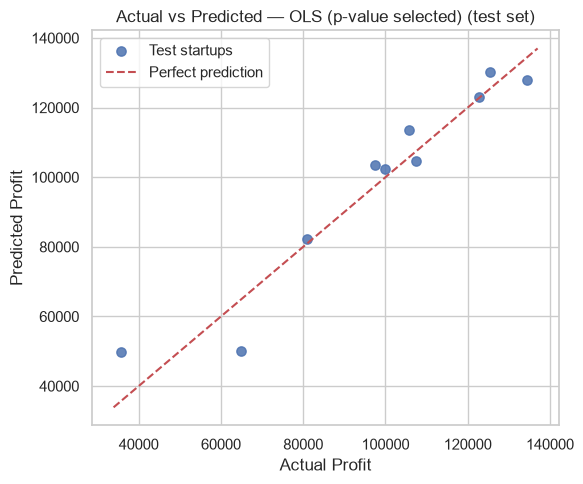

,Actual,Predicted,Residual
13,134307.35,127862.21,6445.14
39,81005.76,82250.56,-1244.80
30,99937.59,102255.72,-2318.13
45,64926.08,50190.47,14735.61
17,125370.37,130136.88,-4766.51
48,35673.41,49799.37,-14125.96
26,105733.54,113638.08,-7904.54
25,107404.34,104535.05,2869.29
32,97427.84,103463.05,-6035.21
19,122776.86,123105.31,-328.45


In [21]:
# Actual vs predicted on the hold-out set
best_pipe = clone(candidates[best_name]).fit(X_train, y_train)
pred_test = best_pipe.predict(X_test)

plt.figure(figsize=(6, 5))
plt.scatter(y_test, pred_test, s=45, alpha=0.85, label="Test startups")
lims = [min(y_test.min(), pred_test.min()) * 0.95, max(y_test.max(), pred_test.max()) * 1.02]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.title(f"Actual vs Predicted — {best_name} (test set)")
plt.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame({"Actual": y_test, "Predicted": pred_test.round(2),
                      "Residual": (y_test - pred_test).round(2)}))

### 5.3 Learning curve — is 50 rows enough?

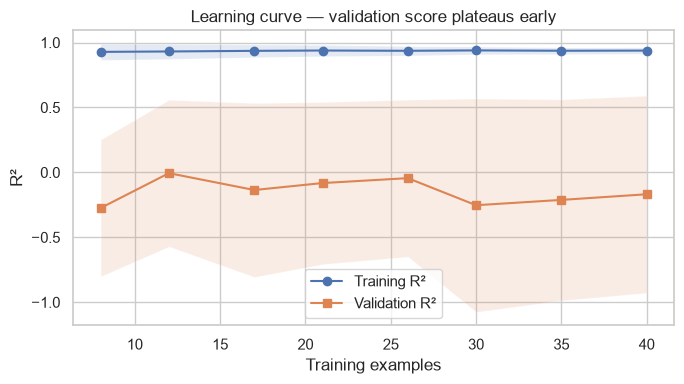

In [22]:
sizes, train_scores, val_scores = learning_curve(
    clone(candidates["OLS (R&D Spend only)"]), X, y, cv=5, shuffle=True,
    random_state=RANDOM_STATE, scoring="r2", train_sizes=np.linspace(0.2, 1.0, 8))

plt.figure(figsize=(7, 4))
plt.plot(sizes, train_scores.mean(1), "o-", label="Training R²")
plt.fill_between(sizes, train_scores.mean(1) - train_scores.std(1),
                 train_scores.mean(1) + train_scores.std(1), alpha=0.15)
plt.plot(sizes, val_scores.mean(1), "s-", label="Validation R²")
plt.fill_between(sizes, val_scores.mean(1) - val_scores.std(1),
                 val_scores.mean(1) + val_scores.std(1), alpha=0.15)
plt.xlabel("Training examples")
plt.ylabel("R²")
plt.title("Learning curve — validation score plateaus early")
plt.legend()
plt.tight_layout()
plt.show()

### 5.4 Model selection

What the numbers above say:

1. **Accuracy is statistically tied across the candidates.** Cross-validated R² spans only 0.934
   (full OLS) to 0.943 (Lasso/ElasticNet) with a standard deviation of ≈ 0.03, so the differences
   are inside the noise band of a 40-row training set.
2. **The hold-out set prefers the simple model.** The R&D-only specification reaches R² = 0.927
   (RMSE ≈ \$7.7 k, MAPE ≈ 9 %) versus 0.899 (RMSE ≈ \$9.1 k) for the full four-predictor model.
3. **Backward elimination keeps only `R&D Spend`.** `State` dummies (p ≈ 0.81 / 1.00),
   `Administration` (p ≈ 0.27) and `Marketing Spend` (p ≈ 0.06) are all insignificant, while
   `R&D Spend` is highly significant (p < 0.001, 95 % CI ≈ 0.80 – 0.91). The reduced model still
   explains R² = 0.947 of the training variance.
4. **Regularisation adds nothing.** Ridge/Lasso/ElasticNet shrink the weak coefficients, but they
   never beat plain OLS — a textbook sign that the extra predictors are noise rather than signal.
5. **Assumptions hold, with one caveat.** Breusch-Pagan p = 0.20 (homoscedastic),
   Durbin-Watson = 1.88 (no autocorrelation), max VIF = 2.50 (no multicollinearity). Shapiro-Wilk
   gives p ≈ 0.007, i.e. residuals are **not perfectly normal** — this is driven by the single
   very-high-profit startup. Non-normality affects the exact p-values/confidence intervals of a
   small sample, not the unbiasedness of the estimates or the accuracy comparison, so the
   conclusion is unchanged.

**Decision:** deploy the **parsimonious R&D-only OLS model** — the same accuracy as the full model
with one coefficient that is directly actionable for budgeting. The full model is kept as a
robustness check (flip `FINAL_MODEL_NAME` in Phase 6 to use it instead).

## 6. Deployment

Deliverables: a persisted pipeline (preprocessing + model in one object), a scoring function with
the same interface as the raw data, and a monitoring plan.

In [23]:
FINAL_MODEL_NAME = "OLS (R&D Spend only)"      # or "OLS (all predictors)"

final_model = clone(candidates[FINAL_MODEL_NAME]).fit(X, y)   # refit on ALL 50 rows
joblib.dump(final_model, MODEL_PATH)

coefs = coef_table(final_model, "coefficient").round(2)
intercept = final_model.named_steps["model"].intercept_
print(f"Saved: {MODEL_PATH}")
print(f"Final model: {FINAL_MODEL_NAME}")
print(f"Intercept: {intercept:,.2f}")
display(coefs)

for fname, coef in coefs["coefficient"].items():
    print(f"  Holding everything else constant, +$1 of {fname} is associated with "
          f"{coef:+,.2f} $ of Profit.")

Saved: startup_profit_model.joblib
Final model: OLS (R&D Spend only)
Intercept: 49,032.90


,coefficient
R&D Spend,0.85


  Holding everything else constant, +$1 of R&D Spend is associated with +0.85 $ of Profit.


In [24]:
loaded_model = joblib.load(MODEL_PATH)

def predict_profit(rd_spend, administration, marketing_spend, state, model=loaded_model):
    """Score one startup. Inputs are validated, then passed to the persisted pipeline."""
    state = str(state).strip().title()
    if state not in {"California", "New York", "Florida"}:
        raise ValueError(f"Unknown State '{state}' - expected California, New York or Florida.")
    row = pd.DataFrame([{
        "R&D Spend": float(rd_spend),
        "Administration": float(administration),
        "Marketing Spend": float(marketing_spend),
        "State": state,
    }])
    return float(model.predict(row)[0])

examples = pd.DataFrame({
    "R&D Spend":       [160000, 120000, 0,      50000],
    "Administration":  [130000, 100000, 90000,  150000],
    "Marketing Spend": [450000, 300000, 120000, 400000],
    "State":           ["California", "Florida", "New York", "New York"],
})
examples["Predicted Profit"] = [round(predict_profit(*r), 2) for r in examples.values]
display(examples)

print(f"Sanity check on training data -> predicted mean "
      f"${final_model.predict(X).mean():,.0f} vs actual mean ${y.mean():,.0f}")

,R&D Spend,Administration,Marketing Spend,State,Predicted Profit
0,160000,130000,450000,California,185719.52
1,120000,100000,300000,Florida,151547.86
2,0,90000,120000,New York,49032.90
3,50000,150000,400000,New York,91747.47


Sanity check on training data -> predicted mean $112,013 vs actual mean $112,013


### 6.3 Monitoring, limitations and next steps

**Monitoring**
* Track live **MAE / MAPE** against realised profit quarterly; alert if MAPE degrades by > 20 %.
* Log every scored request (inputs, prediction, timestamp) to enable drift analysis on
  `R&D Spend` distribution and the `State` mix.
* Refit when new labelled data arrives (~20+ records) or when the input distribution drifts.

**Limitations**
* Only **50 observations** — coefficients carry wide confidence intervals and the model should be
  used for direction/magnitude of effects, not precise forecasts.
* `Administration`, `Marketing Spend` and `State` are statistically insignificant here; a real
  marketing effect may be non-linear or lagged, which this dataset cannot capture.
* The data are historical and (semi-)synthetic: no inflation adjustment, no industry or age of the
  company, no interaction terms.

**Next steps**
* Add polynomial / interaction features (e.g. `R&D x Marketing`) and compare against a
  gradient-boosting model; retest whether linearity is a real limitation.
* Simulate cost-benefit: use the R&D coefficient to recommend a reallocation of the administration
  budget towards R&D.
* Wrap the pipeline in a FastAPI endpoint / dashboard for non-technical stakeholders.